# Od zdarzeń do grafu: jak powstaje jeden zrzut stanu gry

Ten notebook pokazuje **ciąg przyczynowo-skutkowy** budowy grafu, krok po kroku, na jednym meczu:

1. kto gra (formacja),
2. gdzie stoi każdy gracz (jego ostatnie zdarzenie),
3. gdzie jest piłka,
4. kto do kogo podał (i kto piłkę stracił),
5. jak z tego powstaje zrzut stanu gry,
6. jak zrzut wygląda na boisku,
7. jak zmienia się w czasie,
8. jak trafia do sieci jako tensor.

Wszystkie kroki dotyczą **tej samej minuty**, żeby liczby w jednym kroku zgadzały się z obrazkiem w następnym.


In [11]:
# dane jednego meczu: zdarzenia, formacje, zawodnicy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Circle, Rectangle

OUT = Path.cwd().parent / "output"
L, S = 105.0, 68.0        # boisko w metrach
OKNO = 5                  # okno podan w minutach
MAX_SWIEZOSC = 10.0       # po tylu minutach "swiezosc" pozycji przestaje rosnac

KOL = ["match_id", "team_side", "player_id", "player_name", "event_type", "outcome_type",
       "expanded_minute", "second", "period_value", "x", "y",
       "receiver_id", "next_player_id", "is_goal", "is_own_goal"]

ev_all = pd.read_csv(OUT / "combined" / "combined_events.csv", usecols=KOL)
ev_all = ev_all[ev_all["period_value"].isin([1, 2])].copy()
ev_all["czas"] = ev_all["expanded_minute"] + ev_all["second"].fillna(0) / 60

# mecz z najwieksza liczba goli - ladniejsza ilustracja
gole_na_mecz = ev_all[ev_all["is_goal"]].groupby("match_id").size()
MATCH = int(gole_na_mecz.idxmax())

ev = ev_all[ev_all["match_id"] == MATCH].sort_values("czas").reset_index(drop=True)
fo = pd.concat([pd.read_csv(f) for f in OUT.glob(f"match_{MATCH}_*_formations.csv")], ignore_index=True)
pl = pd.concat([pd.read_csv(f) for f in OUT.glob(f"match_{MATCH}_*_players.csv")], ignore_index=True)

# przyklad: minuta tuz przed golem padnietym okolo 60. minuty
gole = ev[ev["is_goal"]]
gol = gole.iloc[(gole["expanded_minute"] - 60).abs().argsort().iloc[0]]
GOL_MINUTA = int(gol["expanded_minute"])
MINUTA = max(12, GOL_MINUTA - 1)

print("mecz:", MATCH, "| zdarzen:", len(ev), "| goli:", len(gole))
print("druzyny:", list(ev["team_side"].unique()), "| formacje (wierszy):", len(fo), "| zawodnicy:", len(pl))
print("wybrany przyklad: minuta %d (gol padl w %d. min, strzelil %s)" % (
    MINUTA, GOL_MINUTA, gol["player_name"]))


mecz: 1824831 | zdarzen: 1562 | goli: 8
druzyny: ['home', 'away'] | formacje (wierszy): 156 | zawodnicy: 40
wybrany przyklad: minuta 55 (gol padl w 56. min, strzelil Mika Biereth)


## Krok 1 — kto gra

Formacja to tabela zmian: każdy wiersz mówi „zawodnik X zajmował slot `slot_number` od minuty `start` do `end`".
Slot 1–11 to jedenastka (slot 0 to kosz — trenerzy, rezerwowi bez wejścia). Żeby wiedzieć, kto gra w minucie `t`,
szukamy wiersza, w którym `start <= t < end`.


In [12]:
# KROK 1: kto zajmuje dany slot w danej minucie (pozycja "w druzynie", nie na boisku)
def kto_w_slocie(strona, slot, minuta):
    f = fo[(fo["team_side"] == strona) & (fo["slot_number"] == slot)]
    f = f[(f["start_minute_expanded"] <= minuta) & (f["end_minute_expanded"] > minuta)]
    return None if f.empty else f.iloc[0]


print("minuta", MINUTA)
for slot in range(1, 12):
    dom = kto_w_slocie("home", slot, MINUTA)
    wyj = kto_w_slocie("away", slot, MINUTA)
    print("  slot %2d | %-24s | %s" % (
        slot,
        "-" if dom is None else dom["player_name"],
        "-" if wyj is None else wyj["player_name"]))

obecni = sum(1 for strona in ("home", "away") for slot in range(1, 12)
             if kto_w_slocie(strona, slot, MINUTA) is not None)
print("\nwezlow graczy: %d z 22 (po jednym na slot)" % obecni)


minuta 55
  slot  1 | Radoslaw Majecki         | Anthony Lopes
  slot  2 | Vanderson                | Marcus Coco
  slot  3 | Caio Henrique            | Kelvin Amian
  slot  4 | Denis Zakaria            | Pedro Chirivella
  slot  5 | Thilo Kehrer             | Saïdou Sow
  slot  6 | Christian Mawissa        | Nicolas Pallois
  slot  7 | Maghnes Akliouche        | Johann Lepenant
  slot  8 | Lamine Camara            | Douglas Augusto
  slot  9 | Mika Biereth             | Matthis Abline
  slot 10 | Takumi Minamino          | -
  slot 11 | Eliesse Ben Seghir       | Moses Simon

wezlow graczy: 21 z 22 (po jednym na slot)


## Krok 2 — gdzie stoi gracz

Pozycji gracza **nie uśredniamy** i nie interpolujemy. Bierzemy jego **ostatnie zdarzenie przed minutą `t`**
i jego surowe współrzędne. Do tego zapisujemy `swiezosc` — ile minut ten event jest już stary (obcinane do 10).

Konsekwencja jest widoczna od razu: niektórzy stoją „na pozycji z 3 minuty temu", bo od tego czasu nic nie zrobili.
Jeśli gracz nie ma jeszcze żadnego zdarzenia, wchodzi pozycja z formacji (`vertical` wzdłuż boiska, `horizontal` w szerz)
i `swiezosc = 10` jako znacznik „brak danych".

Dwie rzeczy do zapamiętania:
- **współrzędne w danych są atakier-relative** (x = 100 to brama przeciwnika), więc graczy gości trzeba odbić lustrem,
- `x * 100/105` to jeszcze nie metry — przeliczamy na boisko 105 × 68 m.


In [13]:
# KROK 2: ostatnie zdarzenie gracza przed minuta + przeliczenie na metry
def pozycja_gracza(player_id, minuta):
    zd = ev[(ev["player_id"] == player_id) & (ev["czas"] <= minuta)]
    if zd.empty:
        return None
    o = zd.iloc[-1]
    return dict(czas=float(o["czas"]), typ=o["event_type"], x=float(o["x"]), y=float(o["y"]))


def na_metry(x, y, strona):
    """Wspolrzedne atakier-relative -> wspolny uklad boiska w metrach (goscie lustrzanie)."""
    if strona == "away":
        x, y = 100 - x, 100 - y
    return x * L / 100, y * S / 100


przyklad = [("home", 4), ("home", 10), ("away", 4), ("away", 9), ("away", 1)]
print("minuta %.0f - skad pochodzi pozycja kazdego z tych graczy:" % MINUTA)
for strona, slot in przyklad:
    r = kto_w_slocie(strona, slot, MINUTA)
    poz = pozycja_gracza(r["player_id"], MINUTA)
    if poz is None:
        print("  %-22s brak zdarzen -> pozycja z formacji" % r["player_name"])
        continue
    x, y = na_metry(poz["x"], poz["y"], strona)
    print("  %-22s ostatni event %5.1f min (%-12s) -> (%5.1f, %5.1f) m | swiezosc %.1f min"
          % (r["player_name"], poz["czas"], poz["typ"], x, y, MINUTA - poz["czas"]))

bez_zdarzen = [r["player_name"] for strona in ("home", "away") for slot in range(1, 12)
               for r in [kto_w_slocie(strona, slot, MINUTA)] if r is not None
               and pozycja_gracza(r["player_id"], MINUTA) is None]
print("\nbez zadnego zdarzenia (pozycja z formacji): %d" % len(bez_zdarzen))


minuta 55 - skad pochodzi pozycja kazdego z tych graczy:
  Denis Zakaria          ostatni event  54.6 min (BallTouch   ) -> ( 49.4,  35.5) m | swiezosc 0.4 min
  Takumi Minamino        ostatni event  54.9 min (Aerial      ) -> ( 85.9,  39.9) m | swiezosc 0.1 min
  Pedro Chirivella       ostatni event  55.0 min (Pass        ) -> ( 75.6,  49.5) m | swiezosc 0.0 min
  Matthis Abline         ostatni event  55.0 min (Foul        ) -> ( 61.5,  51.3) m | swiezosc 0.0 min
  Anthony Lopes          ostatni event  53.4 min (Pass        ) -> (101.1,  35.9) m | swiezosc 1.6 min

bez zadnego zdarzenia (pozycja z formacji): 0


## Krok 3 — gdzie jest piłka

Piłka to węzeł 22 i działa dokładnie tak samo jak gracze: bierzemy jej **ostatnie zdarzenie z realną pozycją**
przed minutą `t`. Dodatkowo zapisujemy, **która drużyna ma posiadanie** — to jedna z cech węzłów graczy.


In [14]:
# KROK 3: gdzie lezy pilka i kto ja ostatni mial
def pilka_w_minucie(minuta):
    zd = ev[ev["czas"] <= minuta]
    if zd.empty:
        return None
    o = zd.iloc[-1]
    return dict(czas=float(o["czas"]), typ=o["event_type"], player_id=o["player_id"],
                nazwa=o["player_name"], strona=o["team_side"], x=float(o["x"]), y=float(o["y"]))


pilka = pilka_w_minucie(MINUTA)
bx, by = na_metry(pilka["x"], pilka["y"], pilka["strona"])
print("minuta %.0f" % MINUTA)
print("  pilka: (%5.1f, %5.1f) m" % (bx, by))
print("  ostatnie zdarzenie: %.2f min | %s | %s (%s)" % (
    pilka["czas"], pilka["typ"], pilka["nazwa"], pilka["strona"]))
print("  posiadanie po stronie: %s" % pilka["strona"])


minuta 55
  pilka: ( 61.5,  51.3) m
  ostatnie zdarzenie: 54.98 min | Foul | Christian Mawissa (home)
  posiadanie po stronie: home


## Krok 4 — krawędzie: podania i straty

Krawędź powstaje z podania, ale w **dwóch osobnych kanałach**:

- `udane` — podanie, które doszło do kolegi z drużyny (to jest macierz `A` w pliku z grafami),
- `straty` — podanie nieudane, przejęte przez rywala (kanał `A_loss`).

Rozdzielenie jest istotne: gdyby oba typy wpadły do jednej macierzy, GAT dostawałby krawędzie łączące
zawodników **różnych drużyn** i nie odróżniłby „gramy ze sobą" od „właśnie nam zabrali piłkę".

Krawędź istnieje tylko wtedy, gdy **oba końce mają węzeł** w tym zrzucie (czyli obaj gracze są na boisku)
i gdy zawodnik nie jest połączony sam ze sobą. Okno: `t - 5 min < czas podania <= t`.


In [15]:
# KROK 4: podania z okna ostatnich OKNO minut, rozdzielone na udane i straty
STRONA_GRACZA = ev.dropna(subset=["player_id"]).groupby("player_id")["team_side"].first().to_dict()
NAZWA = dict(zip(pl["player_id"], pl["player_name"]))


def podania_w_oknie(minuta, okno=OKNO):
    p = ev[(ev["event_type"] == "Pass") & (ev["czas"] > minuta - okno) & (ev["czas"] <= minuta)].copy()
    p["odbiorca"] = p["receiver_id"].fillna(p["next_player_id"])
    p["strona_odbiorcy"] = p["odbiorca"].map(STRONA_GRACZA)
    p = p[p["strona_odbiorcy"].notna()]
    p["udane"] = (p["outcome_type"] == "Successful") & (p["strona_odbiorcy"] == p["team_side"])
    return p


podania = podania_w_oknie(MINUTA)
print("podan w oknie %.0f-%.0f min: %d | udanych %d | strat %d" % (
    MINUTA - OKNO, MINUTA, len(podania), int(podania["udane"].sum()), int((~podania["udane"]).sum())))

print("\npierwsze udane podania (krawedz w kanale A):")
for _, r in podania[podania["udane"]].head(6).iterrows():
    print("  %5.1f min | %-22s -> %-22s" % (r["czas"], r["player_name"], NAZWA.get(r["odbiorca"], "?")))

print("\nstraty (krawedz w kanale A_loss):")
for _, r in podania[~podania["udane"]].head(4).iterrows():
    print("  %5.1f min | %-22s -> %-22s (przejal rywal)" % (
        r["czas"], r["player_name"], NAZWA.get(r["odbiorca"], "?")))


podan w oknie 50-55 min: 49 | udanych 39 | strat 10

pierwsze udane podania (krawedz w kanale A):
   50.2 min | Denis Zakaria          -> Eliesse Ben Seghir    
   50.2 min | Eliesse Ben Seghir     -> Maghnes Akliouche     
   50.3 min | Maghnes Akliouche      -> Vanderson             
   50.5 min | Vanderson              -> Maghnes Akliouche     
   50.5 min | Maghnes Akliouche      -> Eliesse Ben Seghir    
   50.5 min | Eliesse Ben Seghir     -> Lamine Camara         

straty (krawedz w kanale A_loss):
   50.0 min | Anthony Lopes          -> Christian Mawissa      (przejal rywal)
   50.1 min | Lamine Camara          -> Matthis Abline         (przejal rywal)
   50.7 min | Caio Henrique          -> Marcus Coco            (przejal rywal)
   51.1 min | Eliesse Ben Seghir     -> Douglas Augusto        (przejal rywal)


## Krok 5 — składamy zrzut stanu gry

Teraz wszystko razem. Jeden zrzut to:

- **23 węzły**: 0–10 gospodarze (sloty 1–11), 11–21 goście, 22 piłka — każdy z 11 cechami,
- **dwie macierze 23 × 23**: `udane` (podania) i `straty` (przejęcia),
- **liczba zdarzeń piłki**: do węzła piłki dochodzi krawędź od gracza, który ją miał.


In [16]:
# KROK 5: jeden zrzut = wezly graczy + pilka + dwie macierze krawedzi
def stan_gry(minuta, okno=OKNO):
    wezly = []
    for strona, baza in (("home", 0), ("away", 11)):
        for slot in range(1, 12):
            r = kto_w_slocie(strona, slot, minuta)
            if r is None:
                continue
            pid = r["player_id"]
            poz = pozycja_gracza(pid, minuta)
            if poz is None:
                x, y = na_metry(float(r["vertical"]) * 10, float(r["horizontal"]) * 10, strona)
                swiezosc, zrodlo = MAX_SWIEZOSC, "formacja"
            else:
                x, y = na_metry(poz["x"], poz["y"], strona)
                swiezosc, zrodlo = min(MAX_SWIEZOSC, minuta - poz["czas"]), "zdarzenie"
            wezly.append(dict(idx=baza + slot - 1, strona=strona, slot=slot, player_id=pid,
                              nazwa=r["player_name"], x=x, y=y, swiezosc=swiezosc, zrodlo=zrodlo))

    pilka = pilka_w_minucie(minuta)
    if pilka is not None:
        pilka["x"], pilka["y"] = na_metry(pilka["x"], pilka["y"], pilka["strona"])

    mapa = {w["player_id"]: w["idx"] for w in wezly}
    udane, straty = {}, {}
    for _, r in podania_w_oknie(minuta, okno).iterrows():
        i, j = mapa.get(r["player_id"]), mapa.get(r["odbiorca"])
        if i is not None and j is not None and i != j:
            cel = udane if r["udane"] else straty
            cel[(i, j)] = cel.get((i, j), 0) + 1

    return dict(minuta=minuta, wezly=wezly, pilka=pilka, udane=udane, straty=straty)


stan = stan_gry(MINUTA)
print("zrzut z minuty", MINUTA)
print("  wezlow: %d (z formacji: %d)" % (
    len(stan["wezly"]), sum(1 for w in stan["wezly"] if w["zrodlo"] == "formacja")))
print("  krawedzi podan: %d | krawedzi strat: %d" % (len(stan["udane"]), len(stan["straty"])))
print("  srednia swiezosc pozycji: %.1f min" % np.mean([w["swiezosc"] for w in stan["wezly"]]))
print("  pilka: (%5.1f, %5.1f) m" % (stan["pilka"]["x"], stan["pilka"]["y"]))


zrzut z minuty 55
  wezlow: 21 (z formacji: 0)
  krawedzi podan: 32 | krawedzi strat: 9
  srednia swiezosc pozycji: 1.2 min
  pilka: ( 61.5,  51.3) m


## Krok 6 — jak zrzut wygląda na boisku

Rysujemy goły stan z kroku 5:

- **szare strzałki** — udane podania (kierunek = kto do kogo, grubość = ile razy w oknie),
- **czerwone przerywane strzałki** — straty (kto podał, kto przejął),
- **kółka** — gracze (niebiescy gospodarze, czerwoni goście, cyfra w środku = slot),
- **gwiazdka** — piłka, z kropkowaną linią do gracza, który ją miał.


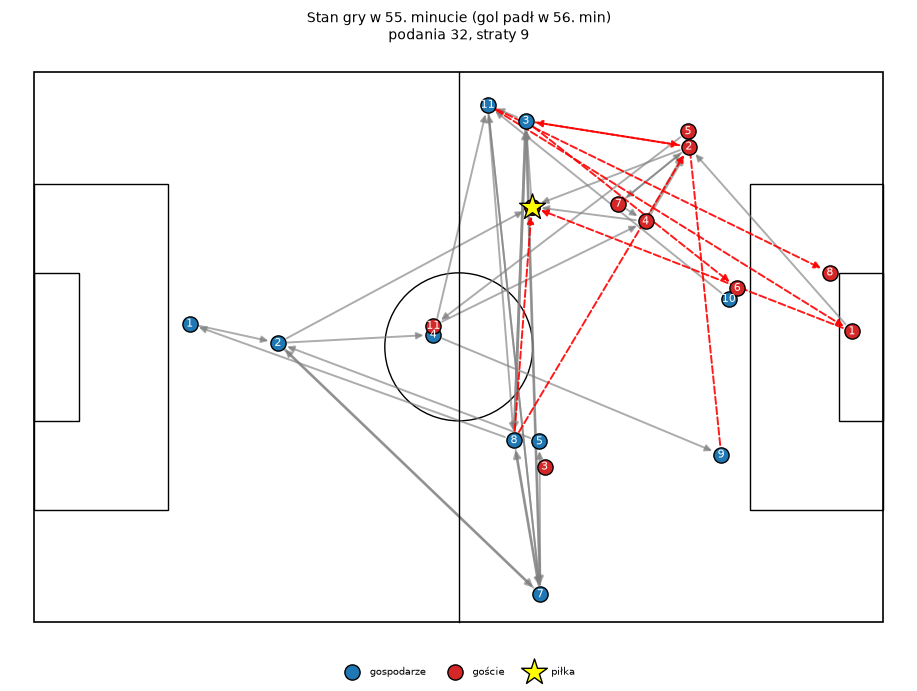

In [17]:
# KROK 6: boisko + wezly + krawedzie (podania ze strzalka, straty przerywana linia)
KOLORY = {"home": "tab:blue", "away": "tab:red"}


def boisko(ax):
    ax.add_patch(Rectangle((0, 0), L, S, fill=False, lw=1.2, color="black"))
    ax.plot([L / 2, L / 2], [0, S], color="black", lw=1)
    ax.add_patch(Circle((L / 2, S / 2), 9.15, fill=False, lw=1))
    for lewa in (True, False):
        x0 = 0 if lewa else L - 16.5
        ax.add_patch(Rectangle((x0, S / 2 - 20.16), 16.5, 40.32, fill=False, lw=1))
        x1 = 0 if lewa else L - 5.5
        ax.add_patch(Rectangle((x1, S / 2 - 9.16), 5.5, 18.32, fill=False, lw=1))
    ax.set_xlim(-3, L + 3)
    ax.set_ylim(-3, S + 3)
    ax.set_aspect("equal")
    ax.axis("off")


def rysuj(ax, stan, tytul=""):
    boisko(ax)
    poz = {w["idx"]: (w["x"], w["y"]) for w in stan["wezly"]}

    for (i, j), ile in stan["udane"].items():
        ax.annotate("", xy=poz[j], xytext=poz[i], zorder=1,
                    arrowprops=dict(arrowstyle="-|>", color="gray", lw=0.8 + 0.6 * ile,
                                    alpha=0.65, shrinkA=7, shrinkB=7))
    for (i, j), ile in stan["straty"].items():
        ax.annotate("", xy=poz[j], xytext=poz[i], zorder=1,
                    arrowprops=dict(arrowstyle="-|>", color="red", lw=1.4, ls="--",
                                    alpha=0.9, shrinkA=7, shrinkB=7))

    for strona in ("home", "away"):
        grupa = [w for w in stan["wezly"] if w["strona"] == strona]
        ax.scatter([w["x"] for w in grupa], [w["y"] for w in grupa], s=120,
                   c=KOLORY[strona], edgecolors="black", zorder=3,
                   label="gospodarze" if strona == "home" else "goście")
        for w in grupa:
            ax.annotate(w["slot"], (w["x"], w["y"]), ha="center", va="center",
                        fontsize=8, color="white", zorder=4)

    p = stan["pilka"]
    if p is not None:
        ax.scatter([p["x"]], [p["y"]], marker="*", s=380, c="yellow",
                   edgecolors="black", zorder=5, label="piłka")
        idx = next((w["idx"] for w in stan["wezly"] if w["player_id"] == p["player_id"]), None)
        if idx is not None:
            ax.plot([poz[idx][0], p["x"]], [poz[idx][1], p["y"]], color="gold", lw=1.5,
                    ls=":", zorder=2)

    ax.set_title(tytul or ("minuta %d" % stan["minuta"]), fontsize=10)
    ax.legend(loc="upper center", fontsize=7, ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.02))


fig, ax = plt.subplots(figsize=(11, 7))
rysuj(ax, stan, "Stan gry w %d. minucie (gol padł w %d. min)\n"
                "podania %d, straty %d" % (MINUTA, GOL_MINUTA, len(stan["udane"]), len(stan["straty"])))
plt.tight_layout()
plt.savefig(OUT / "figures" / "graf_stan_gry.png", dpi=130)
plt.show()


## Krok 7 — jak zrzut zmienia się w czasie

Jeden zrzut to jedna klatka. Sieć dostaje **sekwencję `T = 10` kolejnych zrzutów** (co minutę), więc liczy się
także to, jak graf się zmienia: gdzie przesuwa się piłka, kto zaczyna grać w innym sektorze, gdzie robi się gęsto.

Poniżej cztery kolejne minuty kończące się tuż przed golem — widać, jak akcja się zawiązuje.


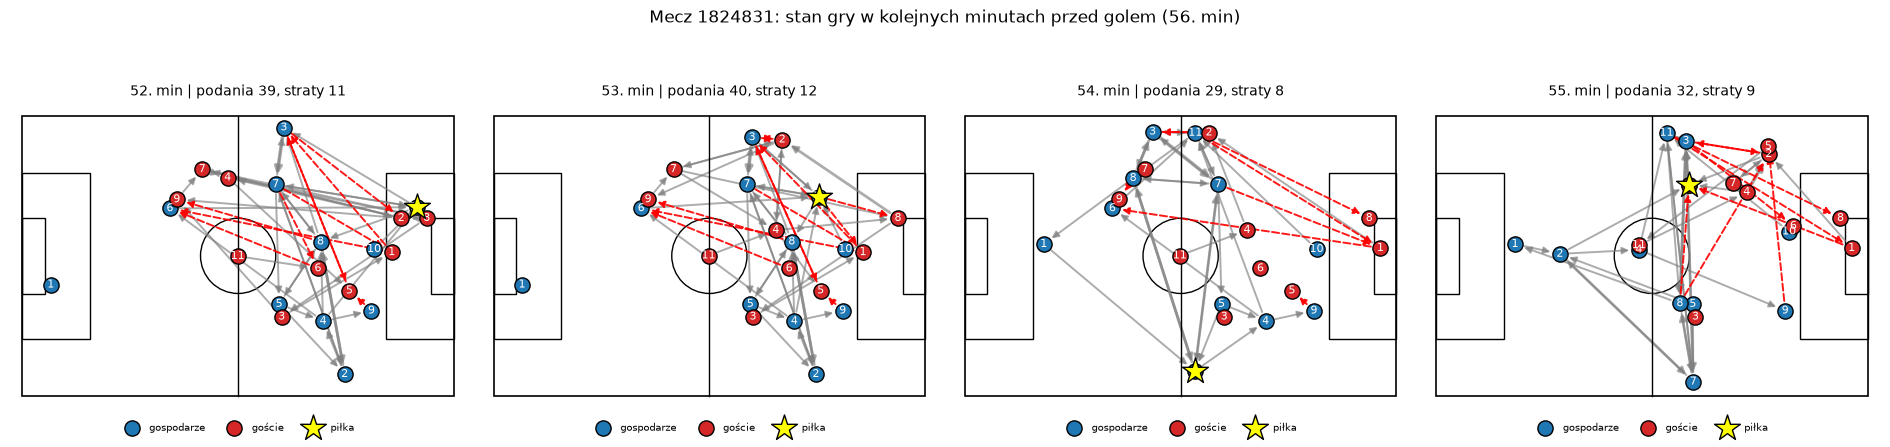

In [18]:
# KROK 7: cztery kolejne minuty przed golem
minuty = [max(12, MINUTA - 3), MINUTA - 2, MINUTA - 1, MINUTA]

fig, osie = plt.subplots(1, 4, figsize=(19, 4.8))
for ax, m in zip(osie, minuty):
    rysuj(ax, stan_gry(m), "%d. min | podania %d, straty %d"
          % (m, len(stan_gry(m)["udane"]), len(stan_gry(m)["straty"])))
fig.suptitle("Mecz %d: stan gry w kolejnych minutach przed golem (%d. min)" % (MATCH, GOL_MINUTA), fontsize=12)
plt.tight_layout()
plt.savefig(OUT / "figures" / "graf_sekwencja.png", dpi=110)
plt.show()


## Krok 8 — jak to trafia do sieci

Do treningu (notebook `05_gat`) idzie nie pojedynczy zrzut, tylko **sekwencja `T = 10` zrzutów** naraz:

| tensor | kształt | co zawiera |
|---|---|---|
| `X` | (zrzuty, 23, 11) | cechy węzłów |
| `A` | (zrzuty, 23, 23) | udane podania w oknie 5 min (znormalizowane) |
| `A_loss` | (zrzuty, 23, 23) | straty w oknie 5 min (surowe liczby) |
| `meta` | (zrzuty, 3) | `match_id`, połowa, minuta |

`A` jest znormalizowana (`log1p / log1p(max)`) tylko dlatego, żeby wagi mieściły się w [0; 1] — GAT i tak używa
z niej wyłącznie progu `> 0` (maska sąsiedztwa). `A_loss` zostawiłem w surowych liczbach, bo w rysunkach
i w analizie „ile razy" jest wygodniejsza.


In [19]:
# KROK 8: tensor cech, macierze krawedzi i sekwencja T=10
d = np.load(OUT / "graphs.npz")
X, A, A_loss, meta = d["X"], d["A"], d["A_loss"], d["meta"]

NAZWY_CECH = ["x", "y", "swiezosc", "gosc", "pozycja_ze_zdarzenia", "bramkarz", "obronca", "pilka",
              "ma_pilke", "posiadanie_mojej_druzyny", "swiezosc_posiadania"]
T = 10

print("wszystkie zrzuty:", X.shape[0], "| X:", X.shape, "| A:", A.shape, "| A_loss:", A_loss.shape)
i = int(np.where((meta[:, 0] == MATCH) & (meta[:, 2] == MINUTA))[0][0])
print("\nzrzut meczu %d, minuta %d -> indeks %d" % (MATCH, MINUTA, i))
print()
print("cechy wezla 0 (bramkarz gospodarzy):")
for nazwa, wartosc in zip(NAZWY_CECH, X[i, 0]):
    print("  %-24s %.3f" % (nazwa, wartosc))
print()
print("wezel 22 (pilka):", np.round(X[i, 22], 3))

podania_A = A[i].copy()
podania_A[22, :] = 0
podania_A[:, 22] = 0
print()
print("krawedzi podan w tensorze: %d | w zrzucie z kroku 5: %d" % (
    int((podania_A > 0).sum()), len(stan["udane"])))
print("krawedzi strat w tensorze: %d | w zrzucie z kroku 5: %d" % (
    int((A_loss[i] > 0).sum()), len(stan["straty"])))
print("krawedzi pilka-gracz:", int((A[i][22] > 0).sum() + (A[i][:, 22] > 0).sum()))
print()
print("sekwencja do sieci = ostatnie %d zrzutow: X %s, A %s" % (
    T, (T, 23, 11), (T, 23, 23)))


wszystkie zrzuty: 30446 | X: (30446, 23, 11) | A: (30446, 23, 23) | A_loss: (30446, 23, 23)

zrzut meczu 1824831, minuta 55 -> indeks 16161

cechy wezla 0 (bramkarz gospodarzy):
  x                        0.183
  y                        0.542
  swiezosc                 0.115
  gosc                     0.000
  pozycja_ze_zdarzenia     1.000
  bramkarz                 1.000
  obronca                  0.000
  pilka                    0.000
  ma_pilke                 0.000
  posiadanie_mojej_druzyny 1.000
  swiezosc_posiadania      0.992

wezel 22 (pilka): [0.586 0.755 0.002 0.5   1.    0.    0.    1.    1.    0.5   0.992]

krawedzi podan w tensorze: 32 | w zrzucie z kroku 5: 32
krawedzi strat w tensorze: 9 | w zrzucie z kroku 5: 9
krawedzi pilka-gracz: 2

sekwencja do sieci = ostatnie 10 zrzutow: X (10, 23, 11), A (10, 23, 23)
